# Неделя 4. Понедельник

## Обучение без учителя


### Кластеризация

### Задание 1

Импортируйте несколько моделей кластеризации: 
* KMeans
* DBSCAN
* https://scikit-learn.org/stable/modules/clustering.html

In [1]:
import sklearn
from sklearn.cluster import KMeans, DBSCAN
import pandas as pd
import yellowbrick
import sklearn

import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import AgglomerativeClustering

from sklearn.metrics import silhouette_score

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import SilhouetteVisualizer

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap
from umap import UMAP

import matplotlib.pyplot as plt

from sklearn.metrics import homogeneity_score, completeness_score

from sklearn.preprocessing import OrdinalEncoder

d:\Elbrus bootcamp\1Phase\Lesson_22\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import matplotlib.cm as cm
import matplotlib

cm.get_cmap = matplotlib.colormaps.get_cmap

Импортируй датасет: `path = 'assets/X_train.txt'`

* В этом файле содержатся датчики мобильного телефона для различных активностей пользователя. Необходимо выявить какие кластеры можно выделить в данных и предположить, каким состояниями они соответствуют (пользователь в покое, идет, сидит и тд.)

* Фичей много, и здесь не особо нужно, что каждая из них значит, однако более детально об эксперименте можно прочитать [тут](https://data.world/uci/human-activity-recognition)

In [5]:
# path = 'assets/X_train.txt'
# pd.read_csv(path, sep='\s+', header=None)

In [3]:
path = 'X_train.txt'
text = pd.read_csv(path, sep=r'\s+', header=None)

In [4]:
text.shape

(7352, 561)

In [5]:
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [6]:
text_preprocessor = preprocessor.fit_transform(text)

In [7]:
text_preprocessor.shape

(7352, 561)

In [8]:
np.isnan(text_preprocessor).sum()

np.int64(0)

1. Примени ряд кластеризационных [моделей](https://scikit-learn.org/stable/modules/clustering.html) на импортированном датасете.

# модели

In [9]:
km = KMeans(3)
ap = AgglomerativeClustering()
dbs = DBSCAN(eps=1.8, min_samples=4)

In [10]:
km_labels = km.fit_predict(text_preprocessor) # fit - изучает структуру данных, predict - присваивает номер кластера
ap_labels = ap.fit_predict(text_preprocessor)
dbs_labels = dbs.fit_predict(text_preprocessor)

# количество кластеров - сколько групп создал алгоритм

In [11]:
print('KMeans:', np.unique(km_labels))
print('Agglomerative:', np.unique(ap_labels))
print('DBSCAN:', np.unique(dbs_labels))

KMeans: [0 1 2]
Agglomerative: [0 1]
DBSCAN: [-1]


In [12]:
print('KMeans:')
print(pd.Series(km_labels).value_counts())

print('\nAgglomerative:')
print(pd.Series(ap_labels).value_counts())

print('\nDBSCAN:')
print(pd.Series(dbs_labels).value_counts())

KMeans:
0    4045
2    2326
1     981
Name: count, dtype: int64

Agglomerative:
1    4066
0    3286
Name: count, dtype: int64

DBSCAN:
-1    7352
Name: count, dtype: int64


# silhouette_score - насколько хорошо объекты распределены по группам

In [13]:
# проверяем качество кластеризации - насколько хорошо объекты распределены по группам
print('KMeans:', silhouette_score(text_preprocessor, km_labels))

print('Agglomerative:', silhouette_score(text_preprocessor, ap_labels))

KMeans: 0.3274077920801447
Agglomerative: 0.396055785173182


2. Определи и зафиксируй количество кластеров, которое наиболее оптимально с точки зрения метрики `silhouette`. Установи библиотеку [`yellowbrick`](https://www.scikit-yb.org/en/latest/api/cluster/silhouette.html) и визуализируй результаты для использованных методов (при использовании метода K-means). 

шкала:
- ближе к 1 — хорошо разделённые кластеры;
- около 0 — кластеры пересекаются;
- ближе к -1 — объекты могут быть распределены неправильно.

# KMeans - silhouette_score

In [14]:
for n in range(2, 11):
    km = KMeans(n_clusters=n, random_state=42)
    km_labels = km.fit_predict(text_preprocessor)
    sil_score = silhouette_score(text_preprocessor, km_labels)
    print(f'n_clusters: {n}, silhouette_score: {sil_score:.3f}')
# Что делает fit_predict():
# - fit — обучает модель;
# - predict — определяет, к какому кластеру относится каждый объект
# Теперь у нас есть метки кластеров km_labels

n_clusters: 2, silhouette_score: 0.397
n_clusters: 3, silhouette_score: 0.327
n_clusters: 4, silhouette_score: 0.161
n_clusters: 5, silhouette_score: 0.131
n_clusters: 6, silhouette_score: 0.109
n_clusters: 7, silhouette_score: 0.111
n_clusters: 8, silhouette_score: 0.090
n_clusters: 9, silhouette_score: 0.084
n_clusters: 10, silhouette_score: 0.082


In [15]:
best_result_km = 2

# визуализация Yellowbrick

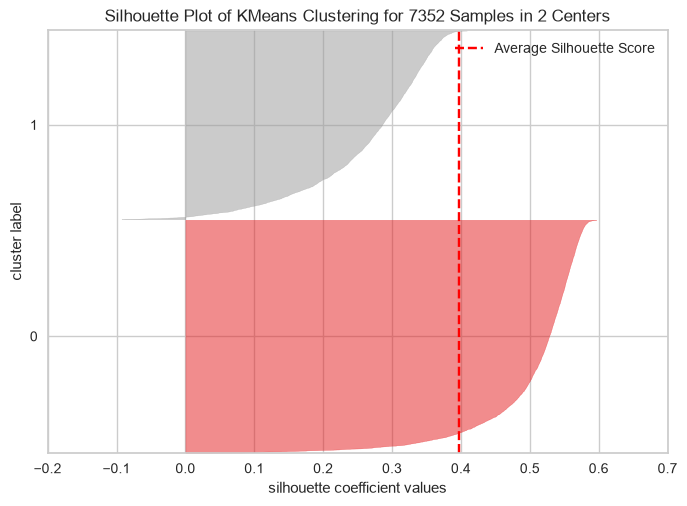

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 7352 Samples in 2 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [16]:
km = KMeans(n_clusters=best_result_km, random_state=42)

visualizer_km = SilhouetteVisualizer(km, force_model=True)
visualizer_km = visualizer_km.fit(text_preprocessor)

visualizer_km.show()

In [17]:
best_result_km = 2
best_silhouette_km = 0.397

Оптимальное количество кластеров для KMeans среди проверенных вариантов — 2.  
Средний Silhouette Score — 0.397.  
Большинство значений положительные, но есть объекты с низкими значениями, поэтому разделение кластеров не идеальное.

# ❓

Почему метрика `silhouette` может быть бессмысленной в некоторых случаях? Приведи пример такой ситуации. 

Метрика Silhouette может быть неприменима, если алгоритм выделил только один кластер или количество кластеров равно количеству объектов. В таких случаях невозможно оценить качество разделения объектов на группы.

4. Примените [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [UMAP](https://umap-learn.readthedocs.io/en/latest/) и [tSNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) декомпозиции и визуализируйте полученные объекты в новом (двумерном или трехмерном) пространстве. В процессе перебирайте возможные параметры и сравнивайте результат по визуализациям.

In [18]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap
from umap import UMAP

pca = PCA(n_components=2)

tsne = TSNE(
    n_components=2, 
    perplexity=30,
    random_state=42
)

ump = umap.UMAP(
    n_components=2, 
    n_neighbors=100,
    random_state=42
)

X_pca = pca.fit_transform(text_preprocessor)
X_tsne = tsne.fit_transform(text_preprocessor)
X_umap = ump.fit_transform(text_preprocessor)

d:\Elbrus bootcamp\1Phase\Lesson_22\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [19]:
print(X_pca.shape)
print(X_tsne.shape)
print(X_umap.shape)

(7352, 2)
(7352, 2)
(7352, 2)


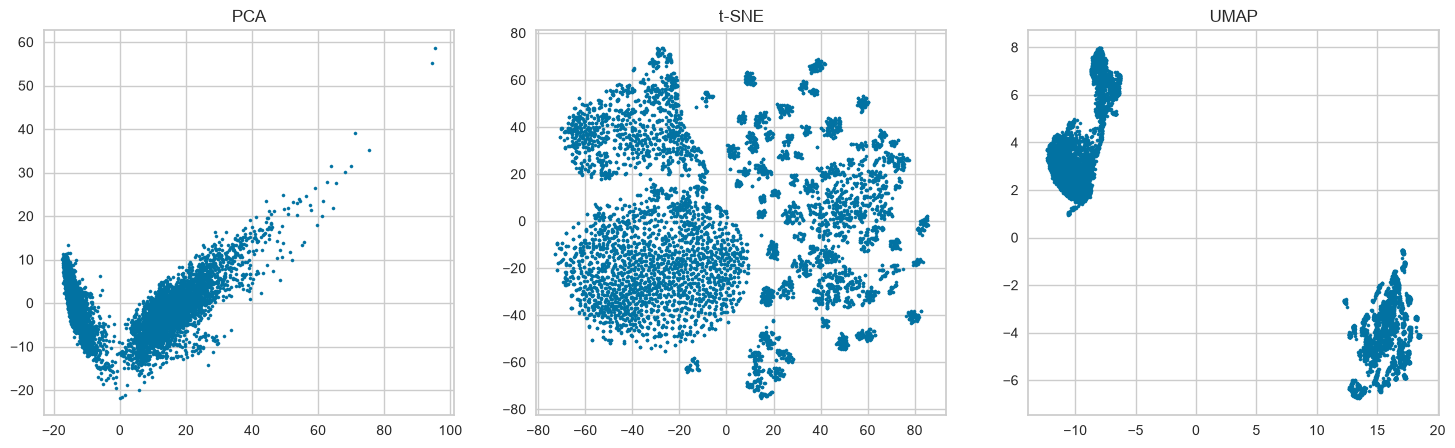

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], s=5)
axes[0].set_title('PCA')

axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], s=5)
axes[1].set_title('t-SNE')

axes[2].scatter(X_umap[:, 0], X_umap[:, 1], s=5)
axes[2].set_title('UMAP')

plt.show()

Теперь можем раскрасить точки по принадлежности к кластерам. Так будет проще увидеть, насколько хорошо методы разделяют данные.

In [20]:
km = KMeans(n_clusters=2, random_state=42)
labels = km.fit_predict(text_preprocessor)

Text(0.5, 1.0, 'UMAP')

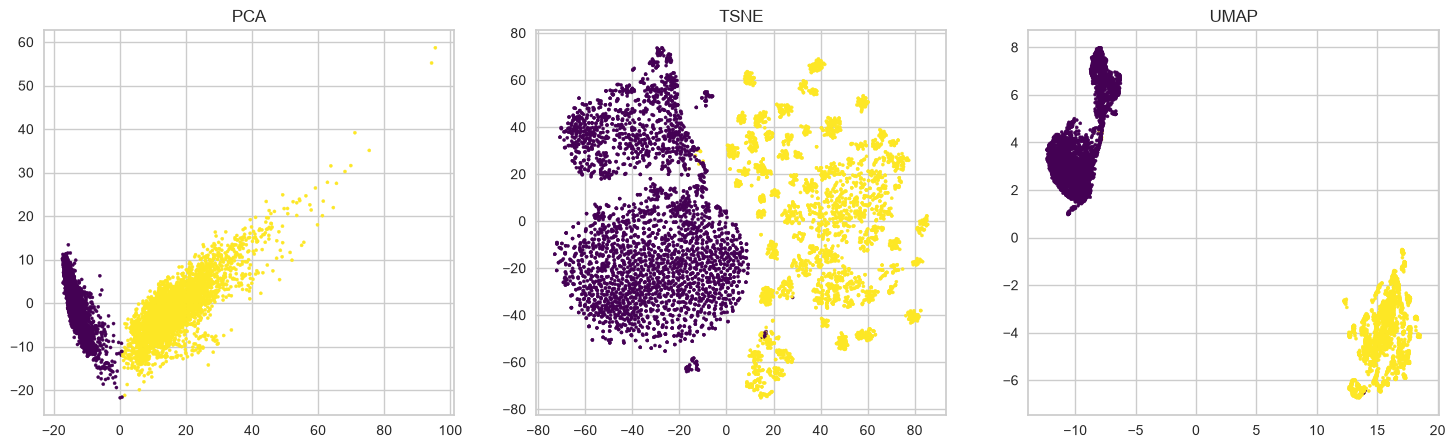

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="viridis", s=5)
axes[0].set_title("PCA")
# : — взять все строки, то есть все объекты.
# 0 — взять столбец с индексом 0, то есть первую координату.
# c=labels — окрашиваем точки в зависимости от кластера.
# cmap='viridis' — выбираем цветовую палитру.
# s - размер точек
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels, cmap="viridis", s=5)
axes[1].set_title("TSNE")

axes[2].scatter(X_umap[:, 0], X_umap[:, 1], c=labels, cmap="viridis", s=5)
axes[2].set_title("UMAP")

In [22]:
print("PCA:", X_pca.shape)
print("t-SNE:", X_tsne.shape)
print("UMAP:", X_umap.shape)

PCA: (7352, 2)
t-SNE: (7352, 2)
UMAP: (7352, 2)


d:\Elbrus bootcamp\1Phase\Lesson_22\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


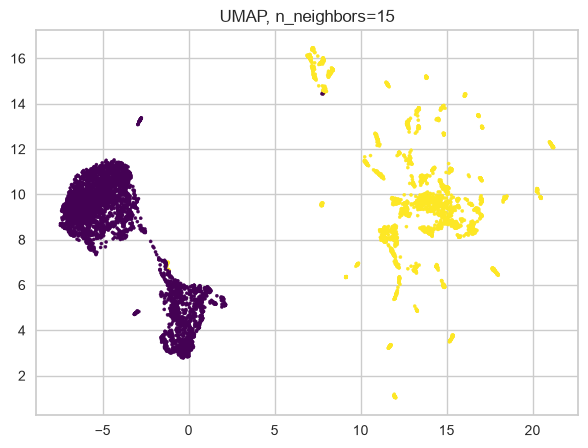

d:\Elbrus bootcamp\1Phase\Lesson_22\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


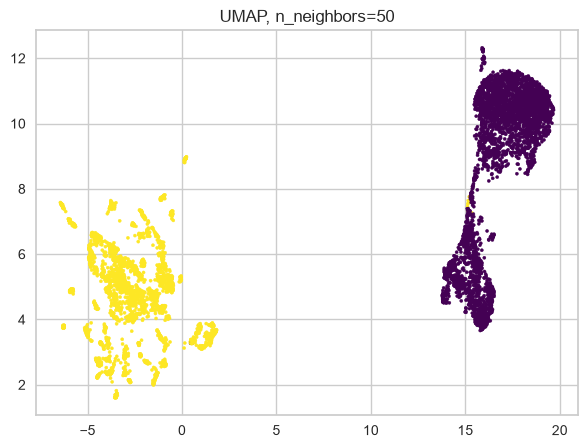

d:\Elbrus bootcamp\1Phase\Lesson_22\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


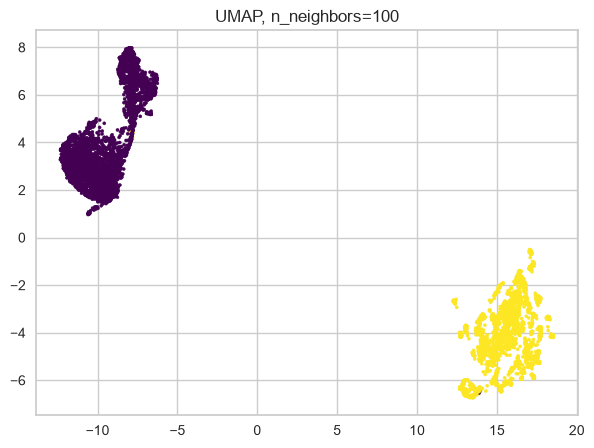

d:\Elbrus bootcamp\1Phase\Lesson_22\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


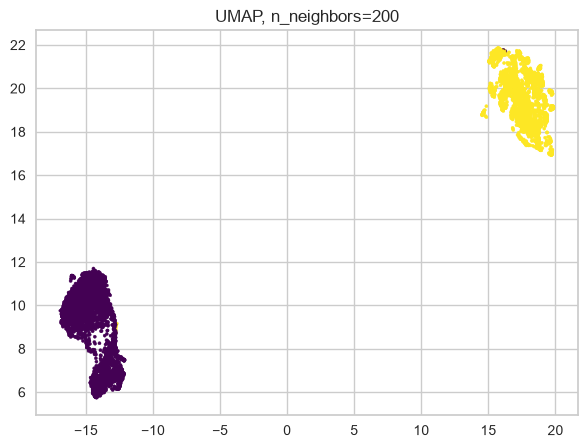

In [23]:
for n in [15, 50, 100, 200]: # разное количество соседей
    umap_model = UMAP(
        n_components=2,
        n_neighbors=n,
        random_state=42
    )

    X_umap = umap_model.fit_transform(text_preprocessor)

    plt.figure(figsize=(7, 5))
    plt.scatter(
        X_umap[:, 0],
        X_umap[:, 1],
        c=labels,
        cmap='viridis',
        s=5
    )
    plt.title(f'UMAP, n_neighbors={n}')
    plt.show()

При увеличении параметра n_neighbors визуальное расположение кластеров изменяется: группы становятся более удалёнными друг от друга. Параметр влияет на баланс между локальной и глобальной структурой данных.

d:\Elbrus bootcamp\1Phase\Lesson_22\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


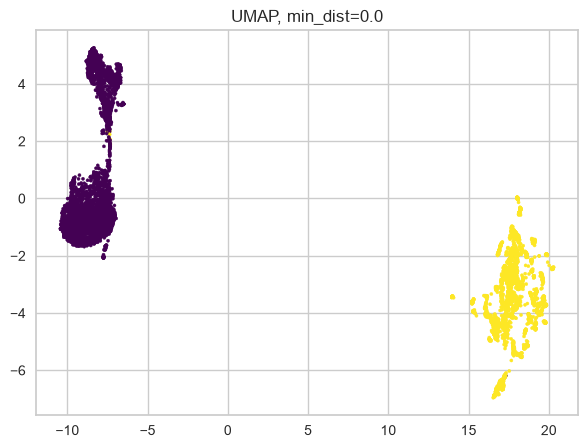

d:\Elbrus bootcamp\1Phase\Lesson_22\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


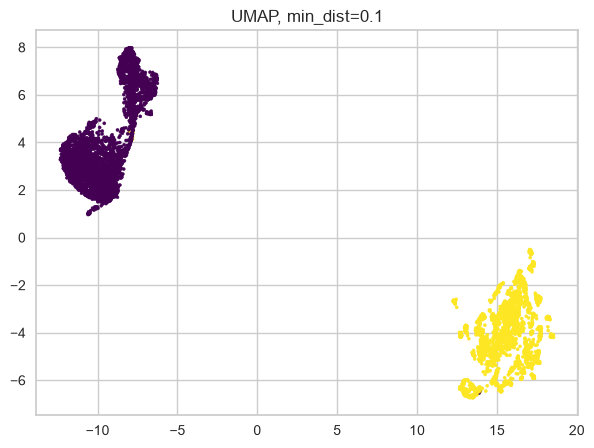

d:\Elbrus bootcamp\1Phase\Lesson_22\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


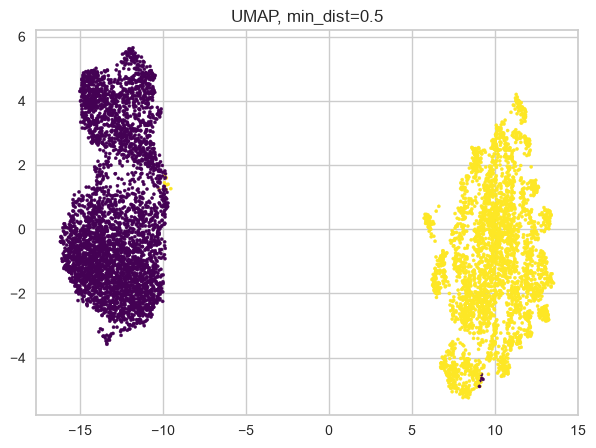

In [ ]:
for d in [0.0, 0.1, 0.5]: # расположение точек друг к другу
    umap_model = UMAP(
        n_components=2,
        n_neighbors=100,
        min_dist=d,
        random_state=42
    )

    X_umap = umap_model.fit_transform(text_preprocessor)

    plt.figure(figsize=(7, 5))
    plt.scatter(
        X_umap[:, 0],
        X_umap[:, 1],
        c=labels,
        cmap='viridis',
        s=5
    )
    plt.title(f'UMAP, min_dist={d}')
    plt.show()

min_dist влияет на плотность расположения точек на двумерной визуализации UMAP.  
min_dist=0.0 — точки могут располагаться очень близко, поэтому группы получаются плотнее.  
min_dist=0.1 — промежуточный вариант.  
min_dist=0.5 — точки распределяются более свободно, группы выглядят размытее.

мы попробовали разные значения n_neighbors и min_dist и сравнили визуализации.

Для визуализации данных в двумерном пространстве были применены три метода снижения размерности: PCA, t-SNE и UMAP.  
- PCA позволяет увидеть общую структуру данных, но не всегда хорошо разделяет группы объектов.  
- t-SNE сохраняет локальные взаимосвязи между объектами и позволяет увидеть отдельные группы.  
- UMAP также выявляет структуру данных. При изменении n_neighbors менялось расположение и расстояние между группами, а при изменении min_dist менялась плотность расположения точек: при значении 0.0 группы были более плотными, при 0.5 — более размытыми.

5. Повтори шаги 1 и 2 для трансформированных данных. 

# KMeans, DBSCAN, Agglomerative - PCA, TSNE, UMAP

KMeans PCA

In [24]:
for n in range(2, 11):
    km = KMeans(n_clusters=n, random_state=42)
    km_labels = km.fit_predict(X_pca)
    sil_score = silhouette_score(X_pca, km_labels)
    print(f'n_clusters: {n}, silhouette_score: {sil_score:.3f}')

n_clusters: 2, silhouette_score: 0.702
n_clusters: 3, silhouette_score: 0.636
n_clusters: 4, silhouette_score: 0.515
n_clusters: 5, silhouette_score: 0.498
n_clusters: 6, silhouette_score: 0.474
n_clusters: 7, silhouette_score: 0.452
n_clusters: 8, silhouette_score: 0.437
n_clusters: 9, silhouette_score: 0.421
n_clusters: 10, silhouette_score: 0.397


KMeans TSNE

In [25]:
for n in range(2, 11):
    km = KMeans(n_clusters=n, random_state=42)
    km_labels = km.fit_predict(X_tsne)
    sil_score = silhouette_score(X_tsne, km_labels)
    print(f'n_clusters: {n}, silhouette_score: {sil_score:.3f}')

n_clusters: 2, silhouette_score: 0.422
n_clusters: 3, silhouette_score: 0.429
n_clusters: 4, silhouette_score: 0.431
n_clusters: 5, silhouette_score: 0.400
n_clusters: 6, silhouette_score: 0.400
n_clusters: 7, silhouette_score: 0.372
n_clusters: 8, silhouette_score: 0.387
n_clusters: 9, silhouette_score: 0.394
n_clusters: 10, silhouette_score: 0.392


KMeans UMAP

In [ ]:
for n in range(2, 11):
    km = KMeans(n_clusters=n, random_state=42)
    km_labels = km.fit_predict(X_umap)
    sil_score = silhouette_score(X_umap, km_labels)
    print(f'n_clusters: {n}, silhouette_score: {sil_score:.3f}')

n_clusters: 2, silhouette_score: 0.847
n_clusters: 3, silhouette_score: 0.636
n_clusters: 4, silhouette_score: 0.461
n_clusters: 5, silhouette_score: 0.428
n_clusters: 6, silhouette_score: 0.428
n_clusters: 7, silhouette_score: 0.422
n_clusters: 8, silhouette_score: 0.402
n_clusters: 9, silhouette_score: 0.396
n_clusters: 10, silhouette_score: 0.376


DBSCAN

In [ ]:
for data, name in [(X_pca, 'PCA'), (X_tsne, 't-SNE'), (X_umap, 'UMAP')]:
    dbs = DBSCAN(eps=1.8, min_samples=4)
    dbs_labels = dbs.fit_predict(data)
    sil_score = silhouette_score(data, dbs_labels)
    print(f'n_clusters: {name}, silhouette_score: {sil_score:.3f}')

n_clusters: PCA, silhouette_score: 0.678
n_clusters: t-SNE, silhouette_score: 0.035
n_clusters: UMAP, silhouette_score: 0.847


Agglomerative

In [ ]:
for data, name in [(X_pca, 'PCA'), (X_tsne, 't-SNE'), (X_umap, 'UMAP')]:
    ap = AgglomerativeClustering(n_clusters=2)
    ap_labels = ap.fit_predict(data)
    sil_score = silhouette_score(data, ap_labels)
    print(f'n_clusters: {name}, silhouette_score: {sil_score:.3f}')

n_clusters: PCA, silhouette_score: 0.701
n_clusters: t-SNE, silhouette_score: 0.422
n_clusters: UMAP, silhouette_score: 0.847


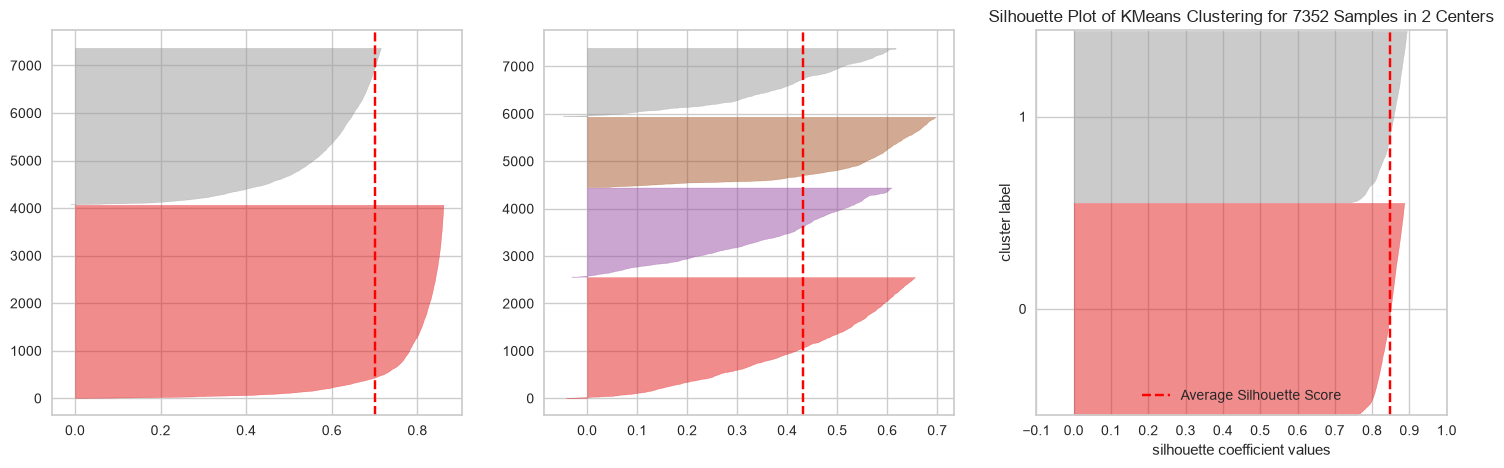

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 7352 Samples in 2 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

km_pca = KMeans(n_clusters=2, random_state=42)
visualizer_km = SilhouetteVisualizer(km_pca, ax=axes[0], force_model=True)
visualizer_km = visualizer_km.fit(X_pca)

km_tsne = KMeans(n_clusters=4, random_state=42)
visualizer_km = SilhouetteVisualizer(km_tsne, ax=axes[1], force_model=True)
visualizer_km = visualizer_km.fit(X_tsne)

km_umap = KMeans(n_clusters=2, random_state=42)
visualizer_km = SilhouetteVisualizer(km_umap, ax=axes[2], force_model=True)
visualizer_km = visualizer_km.fit(X_umap)

visualizer_km.show()

6. Сделай вывод: какой метод кластеризации и какие преобразования данных дают наилучший результат в контексте метрики силует. 

По результатам экспериментов наилучшее значение метрики Silhouette Score показало преобразование данных с помощью UMAP — 0.847.

При использовании UMAP все три алгоритма кластеризации (KMeans, DBSCAN и Agglomerative) показали одинаковое значение метрики — 0.847.

Среди остальных преобразований:
- PCA показал хорошие результаты: KMeans — 0.702, Agglomerative — 0.701, DBSCAN — 0.678.
- t-SNE показал более низкие результаты: KMeans — 0.431, Agglomerative — 0.422, DBSCAN — 0.035.
Таким образом, в рамках проведённого эксперимента UMAP в сочетании с любым из трёх алгоритмов кластеризации показал наилучший результат по метрике Silhouette Score.

7. Визуализируй наиболее успешный результат, цветом выдели кластеры

У нас лучший Silhouette Score — 0.847, и его показали все три алгоритма на UMAP,  
поэтому для визуализации возьмём KMeans на UMAP

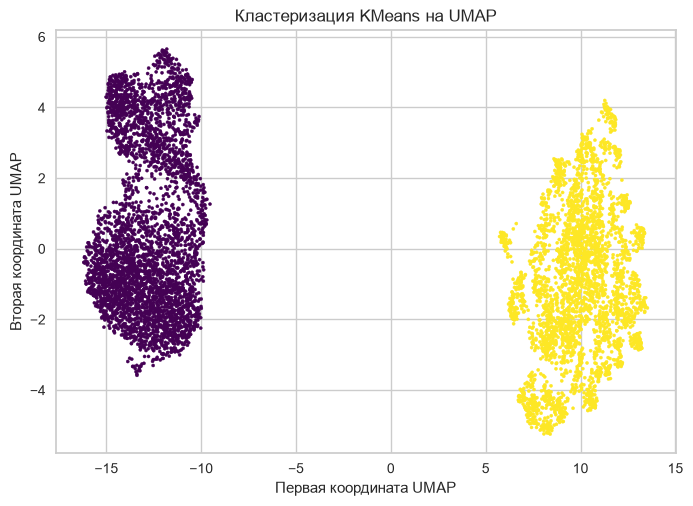

In [ ]:
km = KMeans(n_clusters=2, random_state=42)
labels_km_umap = km.fit_predict(X_umap) # Распределяет данные по группам, определяют кластеры → fit_predict

plt.scatter(X_umap[:, 0], X_umap[:, 1], c=labels_km_umap, cmap="viridis", s=5)

plt.xlabel("Первая координата UMAP")
plt.ylabel("Вторая координата UMAP")
plt.title("Кластеризация KMeans на UMAP")

plt.show()


8. Теперь настало время внешних метрик.

* Подгрузи файл `y_train.txt`. В нем разметка реальных активностей человека, [здесь](https://data.world/uci/human-activity-recognition) можно найти какой класс - какая активность.
* Посчитай внешние метрики $homogenity$ и $completeness$.
* Выбери оптимальное количество кластеров в контексте внешних метрик

In [ ]:
path = 'assets/y_train.txt'

y_train = pd.read_csv(
    'y_train.txt',
    sep=r'\s+',
    header=None
).squeeze()

In [ ]:
print(y_train.shape)
print(y_train.value_counts().sort_index())

(7352,)
0
1    1226
2    1073
3     986
4    1286
5    1374
6    1407
Name: count, dtype: int64


In [ ]:
homogeneity_score_y_train = homogeneity_score(y_train, labels_km_umap)
completeness_score_y_train = completeness_score(y_train, labels_km_umap)

print(f"Homogeneity: {homogeneity_score_y_train:.3f}")
print(f"Completeness: {completeness_score_y_train:.3f}")

Homogeneity: 0.384
Completeness: 0.995


Homogeneity = 0.384 — довольно низкая. Значит, в одном кластере смешаны объекты разных реальных активностей.  
Completeness = 0.995 — почти идеальная.  
Значит, объекты каждой реальной активности практически не разделились между разными кластерами.

In [ ]:
for n in range(2, 11): # проверяем оптимальное значение кластеров
    km = KMeans(n_clusters=n, random_state=42)
    labels = km.fit_predict(X_umap)

    homogeneity = homogeneity_score(y_train, labels)
    completeness = completeness_score(y_train, labels)

    print(f"Clusters: {n}, Homogeneity: {homogeneity:.3f}, Completeness: {completeness:.3f}")

Clusters: 2, Homogeneity: 0.384, Completeness: 0.995
Clusters: 3, Homogeneity: 0.433, Completeness: 0.777
Clusters: 4, Homogeneity: 0.596, Completeness: 0.785
Clusters: 5, Homogeneity: 0.591, Completeness: 0.658
Clusters: 6, Homogeneity: 0.618, Completeness: 0.618
Clusters: 7, Homogeneity: 0.614, Completeness: 0.572
Clusters: 8, Homogeneity: 0.623, Completeness: 0.543
Clusters: 9, Homogeneity: 0.623, Completeness: 0.512
Clusters: 10, Homogeneity: 0.628, Completeness: 0.490


При увеличении количества кластеров Homogeneity растёт, а Completeness снижается.  
При 6 кластерах обе метрики имеют одинаковое значение 0.618, что указывает на сбалансированный результат.  
Поэтому в качестве оптимального варианта по балансу внешних метрик можно выбрать 6 кластеров.

<img src="https://icons.iconarchive.com/icons/icons8/windows-8/256/Programming-Github-icon.png" width=32 /> Пора закоммить изменения в файле. Сделай это с сообщением: 
`"Clustering: task 1 finished"`

После коммита выполни `!git status` в ячейке ниже. 

### Задание 2

Скачай с kaggle [датасет](https://www.kaggle.com/arjunbhasin2013/ccdata) с информацией об обладателях кредитных карт. Кластеризируй объекты и проанализируй результат. 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [ ]:
df = pd.read_csv('CC GENERAL.csv')

display(df.head())

print(df.shape)
df.info()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000


(8950, 10)
<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
dtypes: float64(9), str(1)
memory usage: 699.3 KB


In [ ]:
print(df.isna().sum().sort_values(ascending=False))

CUST_ID                             0
BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
dtype: int64


<img src="https://icons.iconarchive.com/icons/icons8/windows-8/256/Programming-Github-icon.png" width=32 /> Сделай пуш на __github__. 

In [ ]:
df = df.drop(columns=['CUST_ID'])

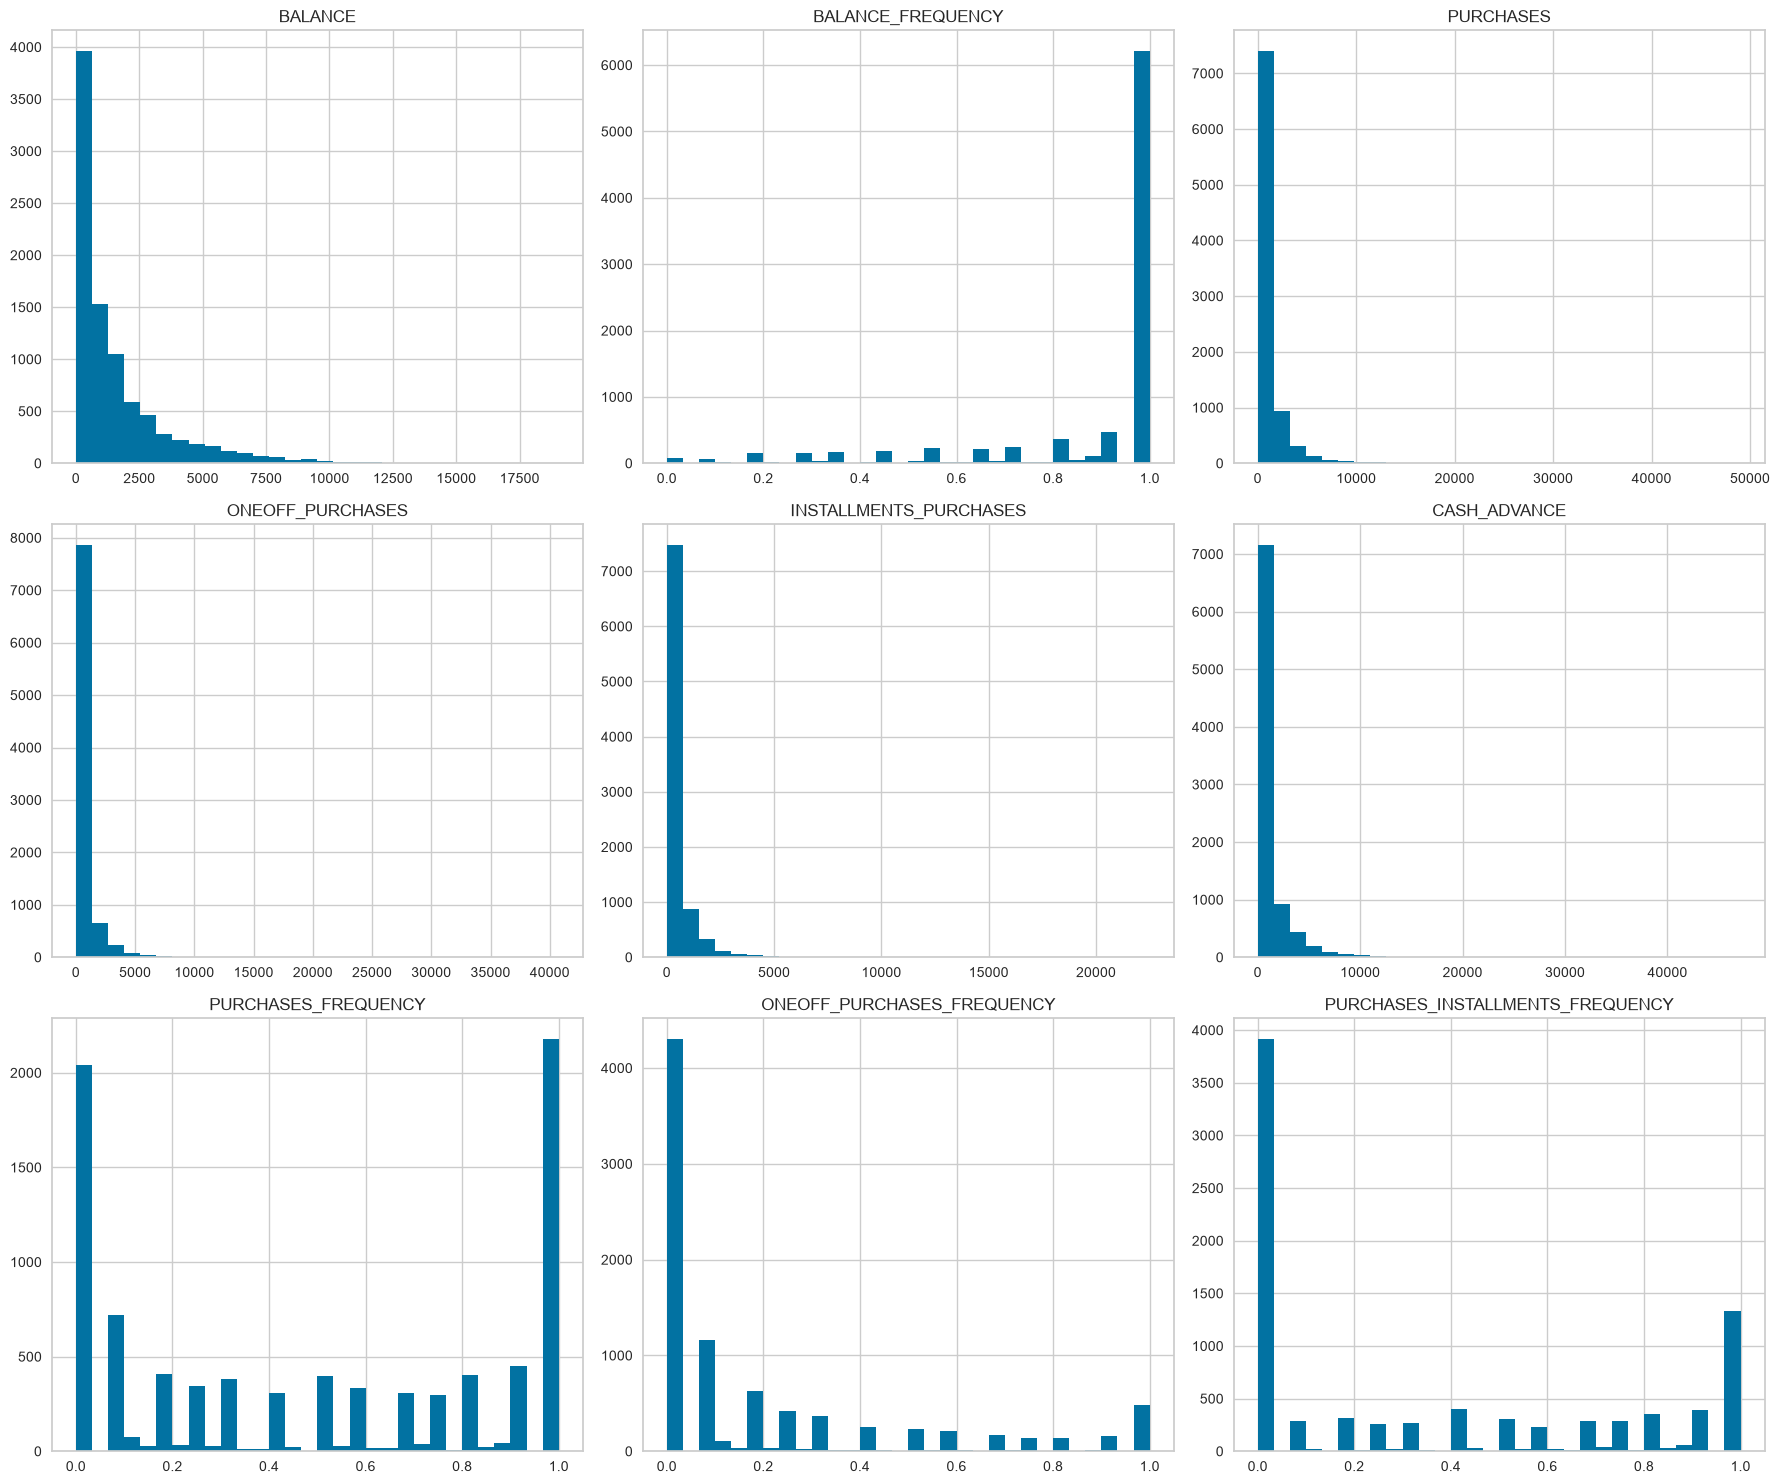

In [ ]:
df.hist(figsize=(18, 15), bins=30)
plt.tight_layout()
plt.show()

In [ ]:
imputer = SimpleImputer(strategy='median')

X = pd.DataFrame(
    imputer.fit_transform(df),
    columns=df.columns
)

print(X.isna().sum().sum())

0


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(8950, 9)


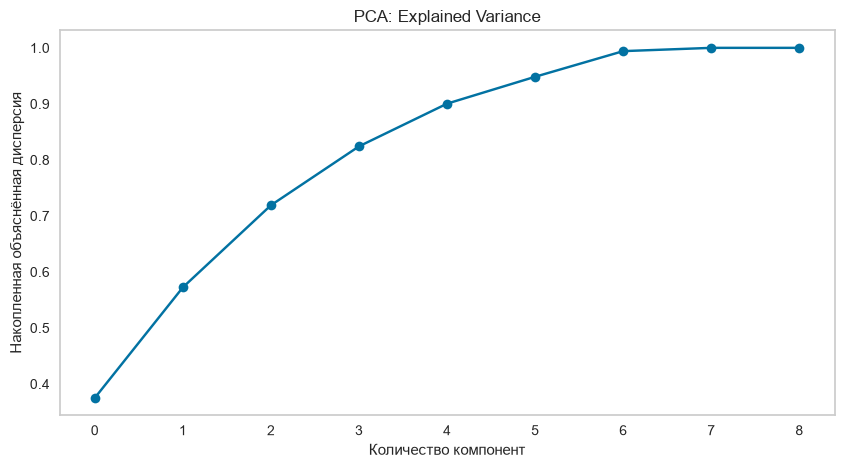

In [ ]:
pca_full = PCA()
pca_full.fit(X_scaled)

plt.figure(figsize=(10, 5))
plt.plot(
    np.cumsum(pca_full.explained_variance_ratio_),
    marker='o'
)
plt.xlabel('Количество компонент')
plt.ylabel('Накопленная объяснённая дисперсия')
plt.title('PCA: Explained Variance')
plt.grid()
plt.show()

In [ ]:
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

print(X_pca.shape)
print(
    'Объяснённая дисперсия:',
    pca.explained_variance_ratio_.sum()
)

(8950, 2)
Объяснённая дисперсия: 0.5725115959914958


In [ ]:
silhouette_scores = []

for n in range(2, 11):
    km = KMeans(n_clusters=n, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f'Clusters: {n}, Silhouette: {score:.3f}')

Clusters: 2, Silhouette: 0.310
Clusters: 3, Silhouette: 0.307
Clusters: 4, Silhouette: 0.321
Clusters: 5, Silhouette: 0.345
Clusters: 6, Silhouette: 0.361
Clusters: 7, Silhouette: 0.369
Clusters: 8, Silhouette: 0.370
Clusters: 9, Silhouette: 0.370
Clusters: 10, Silhouette: 0.362


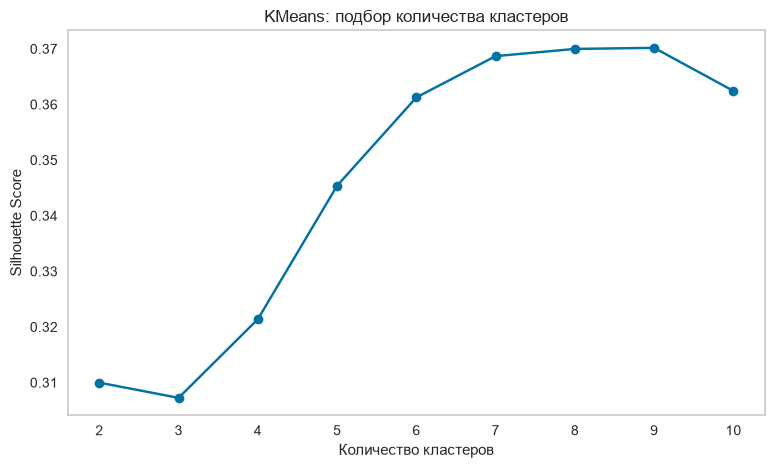

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.xlabel('Количество кластеров')
plt.ylabel('Silhouette Score')
plt.title('KMeans: подбор количества кластеров')
plt.xticks(range(2, 11))
plt.grid()
plt.show()

In [ ]:
best_k = range(2, 11)[np.argmax(silhouette_scores)]

print('Оптимальное количество кластеров:', best_k)

Оптимальное количество кластеров: 9


In [ ]:
km = KMeans(n_clusters=best_k, random_state=42, n_init=10)

labels_km = km.fit_predict(X_scaled)

print('Silhouette:', silhouette_score(X_scaled, labels_km))

Silhouette: 0.37017064802005956


In [ ]:
dbscan = DBSCAN(eps=2, min_samples=5)

labels_dbscan = dbscan.fit_predict(X_scaled)

print('Количество кластеров:', len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0))
print('Количество шумовых объектов:', sum(labels_dbscan == -1))

Количество кластеров: 1
Количество шумовых объектов: 92


In [ ]:
if 1 < len(set(labels_dbscan)) < len(labels_dbscan):
    print('Silhouette:', silhouette_score(X_scaled, labels_dbscan))
else:
    print('Silhouette невозможно корректно рассчитать.')

Silhouette: 0.7244938099062497


In [ ]:
ag_scores = []

for n in range(2, 11):
    ag = AgglomerativeClustering(n_clusters=n)

    labels_ag = ag.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels_ag)
    ag_scores.append(score)

    print(f'Clusters: {n}, Silhouette: {score:.3f}')

Clusters: 2, Silhouette: 0.269
Clusters: 3, Silhouette: 0.241
Clusters: 4, Silhouette: 0.249
Clusters: 5, Silhouette: 0.290
Clusters: 6, Silhouette: 0.255
Clusters: 7, Silhouette: 0.270
Clusters: 8, Silhouette: 0.271
Clusters: 9, Silhouette: 0.276
Clusters: 10, Silhouette: 0.277


In [ ]:
best_ag = range(2, 11)[np.argmax(ag_scores)]

print('Оптимальное количество кластеров:', best_ag)

Оптимальное количество кластеров: 5


In [ ]:
results = pd.DataFrame({
    'Method': ['KMeans', 'DBSCAN', 'Agglomerative'],
    'Silhouette': [
        max(silhouette_scores),
        silhouette_score(X_scaled, labels_dbscan)
        if 1 < len(set(labels_dbscan)) < len(labels_dbscan)
        else np.nan,
        max(ag_scores)
    ]
})

display(results.sort_values('Silhouette', ascending=False))

,Method,Silhouette
1,DBSCAN,0.724494
0,KMeans,0.370171
2,Agglomerative,0.290138


In [ ]:
best_k = 5

km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
labels_km = km.fit_predict(X_scaled)

print(pd.Series(labels_km).value_counts().sort_index())

0    3497
1     103
2    1443
3    2505
4    1402
Name: count, dtype: int64


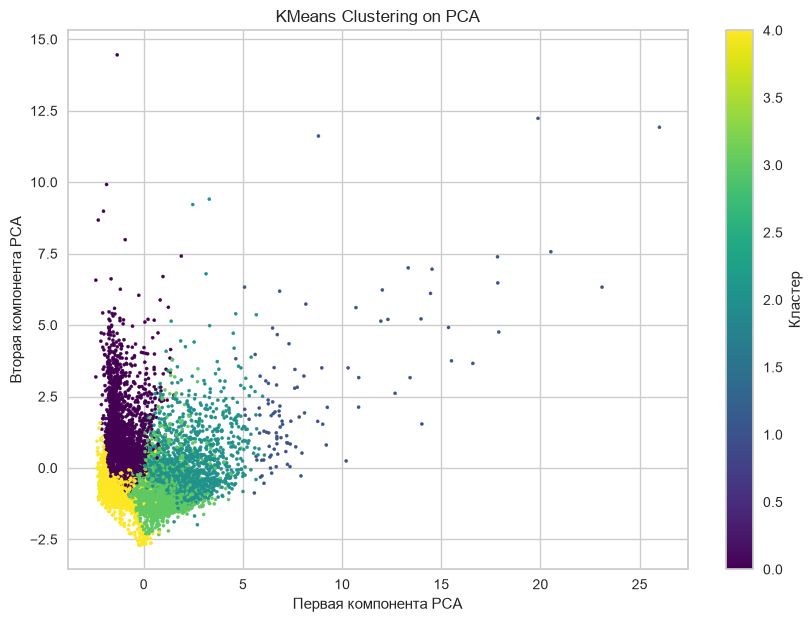

In [ ]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_km,
    cmap='viridis',
    s=5
)

plt.xlabel('Первая компонента PCA')
plt.ylabel('Вторая компонента PCA')
plt.title('KMeans Clustering on PCA')
plt.colorbar(label='Кластер')
plt.show()

In [ ]:
df_result = X.copy()

df_result['Cluster'] = labels_km

# Средние значения признаков по каждому кластеру
cluster_profile = df_result.groupby('Cluster').mean().round(2)

display(cluster_profile)

# Количество объектов в каждом кластере
print('Количество объектов:')
print(df_result['Cluster'].value_counts().sort_index())

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY
Cluster,,,,,,,,,
0,2330.37,0.97,230.50,186.66,44.01,1779.41,0.13,0.08,0.05
1,4345.91,0.98,14639.70,9558.49,5081.21,914.56,0.92,0.72,0.79
2,1872.01,0.98,2666.37,1997.08,669.30,628.77,0.89,0.77,0.50
3,1004.41,0.95,942.00,197.61,745.10,402.47,0.87,0.09,0.82
4,133.93,0.39,326.28,205.60,120.90,377.04,0.26,0.08,0.17


Количество объектов:
Cluster
0    3497
1     103
2    1443
3    2505
4    1402
Name: count, dtype: int64


Кластер	Особенности	Предварительное название  
0	Низкие покупки, низкая частота покупок, высокий Cash Advance	Редко покупающие, часто использующие наличные авансы  
1	Очень большие покупки, высокая частота покупок и высокий баланс	Активные клиенты с крупными расходами  
2	Высокая частота покупок, преимущественно разовые покупки	Активные покупатели  
3	Частые покупки в рассрочку, мало разовых покупок	Клиенты, предпочитающие рассрочку  
4	Очень низкий баланс и невысокая частота операций	Малоактивные клиенты  

In [ ]:
print('Количество объектов в кластерах DBSCAN:')
print(pd.Series(labels_dbscan).value_counts().sort_index())

print('\nКоличество кластеров без шума:')
print(len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0))

print('\nКоличество объектов, отнесённых к шуму:')
print((labels_dbscan == -1).sum())

Количество объектов в кластерах DBSCAN:
-1      92
 0    8858
Name: count, dtype: int64

Количество кластеров без шума:
1

Количество объектов, отнесённых к шуму:
92


In [ ]:
for eps in [0.5, 1, 1.5, 2, 2.5, 3]:
    db = DBSCAN(eps=eps, min_samples=5)
    labels = db.fit_predict(X_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()

    print(
        f'eps={eps}: '
        f'кластеры={n_clusters}, '
        f'шум={n_noise}'
    )

eps=0.5: кластеры=18, шум=1936
eps=1: кластеры=4, шум=474
eps=1.5: кластеры=2, шум=171
eps=2: кластеры=1, шум=92
eps=2.5: кластеры=1, шум=55
eps=3: кластеры=1, шум=39


In [ ]:
dbscan = DBSCAN(eps=1, min_samples=5)

labels_dbscan = dbscan.fit_predict(X_scaled)

mask = labels_dbscan != -1

score_dbscan = silhouette_score(
    X_scaled[mask],
    labels_dbscan[mask]
)

print('Silhouette DBSCAN:', round(score_dbscan, 3))

print('\nРаспределение объектов:')
print(pd.Series(labels_dbscan).value_counts().sort_index())

Silhouette DBSCAN: 0.376

Распределение объектов:
-1     474
 0    8459
 1       6
 2       5
 3       6
Name: count, dtype: int64


In [ ]:
dbscan = DBSCAN(eps=0.5, min_samples=5)

labels_dbscan = dbscan.fit_predict(X_scaled)

print(
    pd.Series(labels_dbscan)
    .value_counts()
    .sort_values(ascending=False)
)

 0     6904
-1     1936
 3       12
 13      11
 7        9
 5        9
 2        8
 4        7
 8        7
 6        6
 1        5
 15       5
 9        5
 10       5
 17       5
 11       4
 16       4
 12       4
 14       4
Name: count, dtype: int64


In [ ]:
print('KMeans Silhouette:', round(max(silhouette_scores), 3))
print('Оптимальное количество кластеров:', best_k)

KMeans Silhouette: 0.37
Оптимальное количество кластеров: 5


In [ ]:
print('Agglomerative Silhouette:', round(max(ag_scores), 3))
print('Оптимальное количество кластеров:', best_ag)

Agglomerative Silhouette: 0.29
Оптимальное количество кластеров: 5


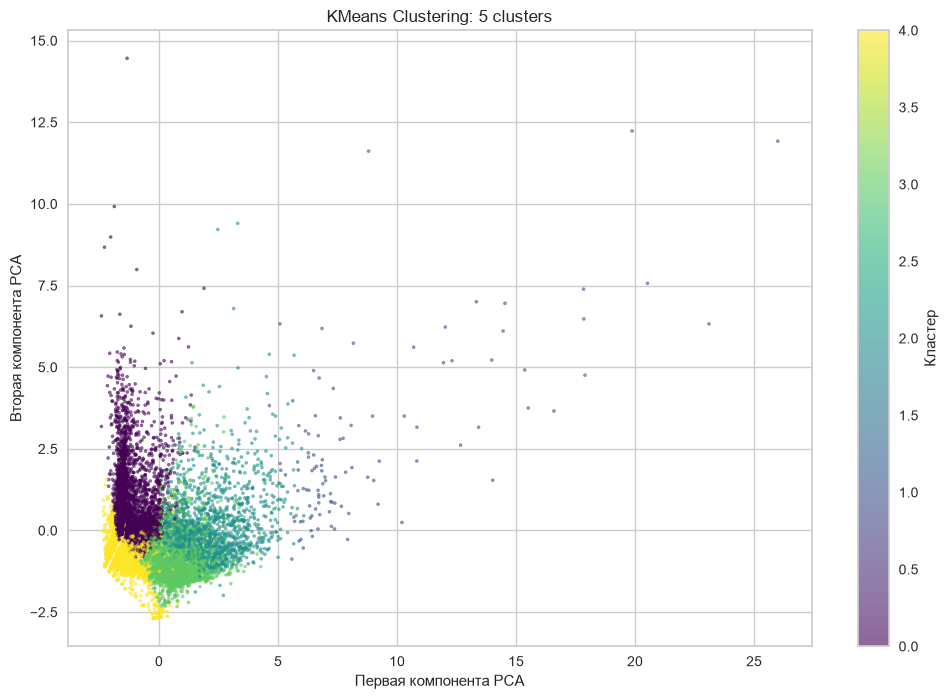

In [ ]:
plt.figure(figsize=(12, 8))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_km,
    cmap='viridis',
    s=5,
    alpha=0.6
)

plt.xlabel('Первая компонента PCA')
plt.ylabel('Вторая компонента PCA')
plt.title('KMeans Clustering: 5 clusters')
plt.colorbar(label='Кластер')
plt.show()

В ходе работы были исследованы три алгоритма кластеризации: KMeans, DBSCAN и Agglomerative Clustering.  
Для оценки качества кластеризации использовалась метрика Silhouette Score.  
Наилучший результат среди методов, формирующих содержательное разделение клиентов, показал KMeans  
с 5 кластерами и Silhouette Score = 0.37.
Agglomerative Clustering также выделил 5 кластеров, однако его Silhouette Score составил 0.29.  
DBSCAN при разных значениях параметра eps преимущественно объединял большинство объектов в один большой  
кластер, выделяя небольшие группы и шум. Поэтому, несмотря на относительно высокий Silhouette Score, 
данный алгоритм оказался менее подходящим для сегментации клиентов.  
По результатам анализа профилей кластеров удалось выделить группы клиентов с различным покупательским   
поведением: активных покупателей, клиентов, предпочитающих рассрочку, малоактивных клиентов и клиентов  
с низкой частотой покупок.
Итог: для данной задачи наиболее подходящим оказался KMeans с 5 кластерами. Он обеспечил более содержательное  
и интерпретируемое разделение клиентов.

# Черновик

In [34]:
kagle = pd.read_csv("CC GENERAL.csv")

In [35]:
kagle.isna().sum()

CUST_ID                             0
BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
dtype: int64

In [36]:
kagle.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
dtypes: float64(9), str(1)
memory usage: 699.3 KB


In [37]:
kagle.dtypes

CUST_ID                                 str
BALANCE                             float64
BALANCE_FREQUENCY                   float64
PURCHASES                           float64
ONEOFF_PURCHASES                    float64
INSTALLMENTS_PURCHASES              float64
CASH_ADVANCE                        float64
PURCHASES_FREQUENCY                 float64
ONEOFF_PURCHASES_FREQUENCY          float64
PURCHASES_INSTALLMENTS_FREQUENCY    float64
dtype: object

In [38]:
kagle.dtypes.reset_index()

,index,0
0,CUST_ID,str
1,BALANCE,float64
2,BALANCE_FREQUENCY,float64
3,PURCHASES,float64
4,ONEOFF_PURCHASES,float64
5,INSTALLMENTS_PURCHASES,float64
6,CASH_ADVANCE,float64
7,PURCHASES_FREQUENCY,float64
8,ONEOFF_PURCHASES_FREQUENCY,float64
9,PURCHASES_INSTALLMENTS_FREQUENCY,float64


In [39]:
kagle["CUST_ID"].unique()

<StringArray>
['C10001', 'C10002', 'C10003', 'C10004', 'C10005', 'C10006', 'C10007',
 'C10008', 'C10009', 'C10010',
 ...
 'C19181', 'C19182', 'C19183', 'C19184', 'C19185', 'C19186', 'C19187',
 'C19188', 'C19189', 'C19190']
Length: 8950, dtype: str

In [40]:
kagle.head(3)

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.0,0.083333
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.0,0.000000
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.0,0.000000


In [ ]:
# imputer = OrdinalEncoder()

# preprocc = imputer.fit_transform(kagle)

In [41]:
kag = kagle.drop(columns=["CUST_ID"])

In [42]:
km = KMeans(n_clusters=3)
ap = AgglomerativeClustering()
dbs = DBSCAN(eps=1.8, min_samples=4)

In [43]:
kag_km  = km.fit_predict(kag)
kag_ap = ap.fit_predict(kag)
kag_dbs = dbs.fit_predict(kag)

In [44]:
print(f"KM: {silhouette_score(kag, kag_km)}")
print(f"Ap: {silhouette_score(kag, kag_ap)}")
print(f"Dds: {silhouette_score(kag, kag_dbs)}")

KM: 0.5853176004858539
Ap: 0.5260639137646717
Dds: -0.41502863913558175


In [45]:
pca = PCA(n_components=2)

tsne = TSNE(
    n_components=2, 
    perplexity=30,
    random_state=42
)

ump = umap.UMAP(
    n_components=2, 
    n_neighbors=50,
    random_state=42
)

kag_pca = pca.fit_transform(kag)
kag_tsne = tsne.fit_transform(kag)
kag_umap = ump.fit_transform(kag)

d:\Elbrus bootcamp\1Phase\Lesson_22\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [46]:
print(f"kag_pca {kag_pca}")
print(f"kag_tsne {kag_tsne}")
print(f"kag_umap {kag_umap}")

kag_pca [[-1785.73512183 -1138.69892778]
 [  531.37298375  5327.90733586]
 [   40.34090231   -92.50621103]
 ...
 [-1748.73430991 -1168.27892469]
 [-1875.06616389 -1090.71160149]
 [ -366.74197966 -1404.58873778]]
kag_tsne [[-83.25058   -19.061543 ]
 [ 24.0154     77.286285 ]
 [ 11.699136    4.424499 ]
 ...
 [-72.00052   -37.072285 ]
 [-75.85299     6.5885987]
 [ 18.105219  -29.877567 ]]
kag_umap [[-3.5814528   7.155558  ]
 [12.900137    0.46964845]
 [ 9.040705    5.5506434 ]
 ...
 [-3.0923579   8.755335  ]
 [-0.8039113   5.1969624 ]
 [ 7.4418483   8.841999  ]]


In [47]:
data = {
    "PCA": kag_pca,
    "TSNE": kag_tsne,
    "UMAP": kag_umap
}

res = []

for k, v in data.items():
    km = KMeans(n_clusters=3)
    kag_km  = km.fit_predict(v)
    silic_score = silhouette_score(v, kag_km)
    res.append(silic_score)
    print(f"{k}: {silic_score:.3f}")

PCA: 0.632
TSNE: 0.378
UMAP: 0.409


In [48]:
res = []

for k, v in data.items():
    ap = AgglomerativeClustering()
    kag_ap = ap.fit_predict(v)
    silic_score = silhouette_score(v, kag_ap)
    res.append(silic_score)
    print(f"{k}: {silic_score:.3f}")

PCA: 0.602
TSNE: 0.328
UMAP: 0.448


In [49]:
res = []

for k, v in data.items():
    dbs = DBSCAN(eps=1.8, min_samples=4)
    kag_dbs = dbs.fit_predict(v)

    unique_labels = set(kag_dbs)

    if -1 in unique_labels:
        unique_labels.remove(-1)

    n_clusters = len(unique_labels)

    if n_clusters > 1:
        silic_score = silhouette_score(v, kag_dbs)
        res.append(silic_score)
        print(f"{k}: {silic_score:.3f}")
    else:
        print(f"{k}: недостаточно кластеров для Silhouette")

PCA: -0.385
TSNE: 0.029
UMAP: недостаточно кластеров для Silhouette


In [50]:
for k, v in data.items():
    dbs = DBSCAN(eps=1.8, min_samples=4)
    kag_dbs = dbs.fit_predict(v)

    print(k, pd.Series(kag_dbs).value_counts().to_dict())

PCA {-1: 8634, 0: 46, 4: 27, 10: 22, 13: 20, 9: 16, 12: 13, 2: 12, 3: 11, 17: 10, 16: 9, 14: 9, 25: 7, 18: 7, 22: 7, 11: 6, 5: 6, 6: 6, 26: 6, 20: 6, 15: 5, 29: 5, 21: 5, 31: 5, 23: 5, 27: 5, 1: 4, 7: 4, 8: 4, 19: 4, 33: 4, 30: 4, 34: 4, 28: 4, 24: 4, 32: 4}
TSNE {37: 456, 18: 407, 16: 347, 24: 343, 9: 338, 31: 335, 0: 319, 33: 276, 1: 271, 29: 259, 22: 236, 25: 234, 17: 223, 52: 218, 6: 190, 43: 187, 2: 172, 4: 170, 32: 164, 65: 163, 14: 152, 55: 144, 44: 139, 38: 131, 39: 109, 53: 105, 58: 100, 47: 97, 34: 94, 50: 83, 28: 75, 11: 74, -1: 73, 51: 72, 3: 67, 67: 67, 82: 66, 10: 64, 78: 63, 7: 58, 62: 58, 73: 58, 26: 57, 63: 56, 5: 55, 36: 55, 42: 54, 49: 50, 8: 49, 20: 47, 45: 45, 93: 44, 30: 43, 74: 43, 92: 41, 21: 38, 97: 37, 59: 36, 57: 35, 69: 33, 104: 33, 85: 33, 15: 32, 87: 32, 91: 31, 99: 31, 66: 29, 71: 29, 72: 28, 80: 26, 96: 26, 41: 24, 46: 23, 27: 22, 56: 22, 54: 21, 12: 20, 83: 20, 79: 19, 84: 19, 68: 17, 88: 17, 89: 17, 100: 17, 23: 16, 76: 14, 13: 13, 61: 13, 75: 13, 81: 

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

data = {
    'PCA': kag_pca,
    'TSNE': kag_tsne,
    'UMAP': kag_umap
}

results = {}

for name, X in data.items():
    results[name] = {}

    km = KMeans(n_clusters=3, random_state=42)
    results[name]['KMeans'] = km.fit_predict(X)

    ag = AgglomerativeClustering(n_clusters=3)
    results[name]['Agglomerative'] = ag.fit_predict(X)

    dbs = DBSCAN(eps=1.8, min_samples=4)
    results[name]['DBSCAN'] = dbs.fit_predict(X)

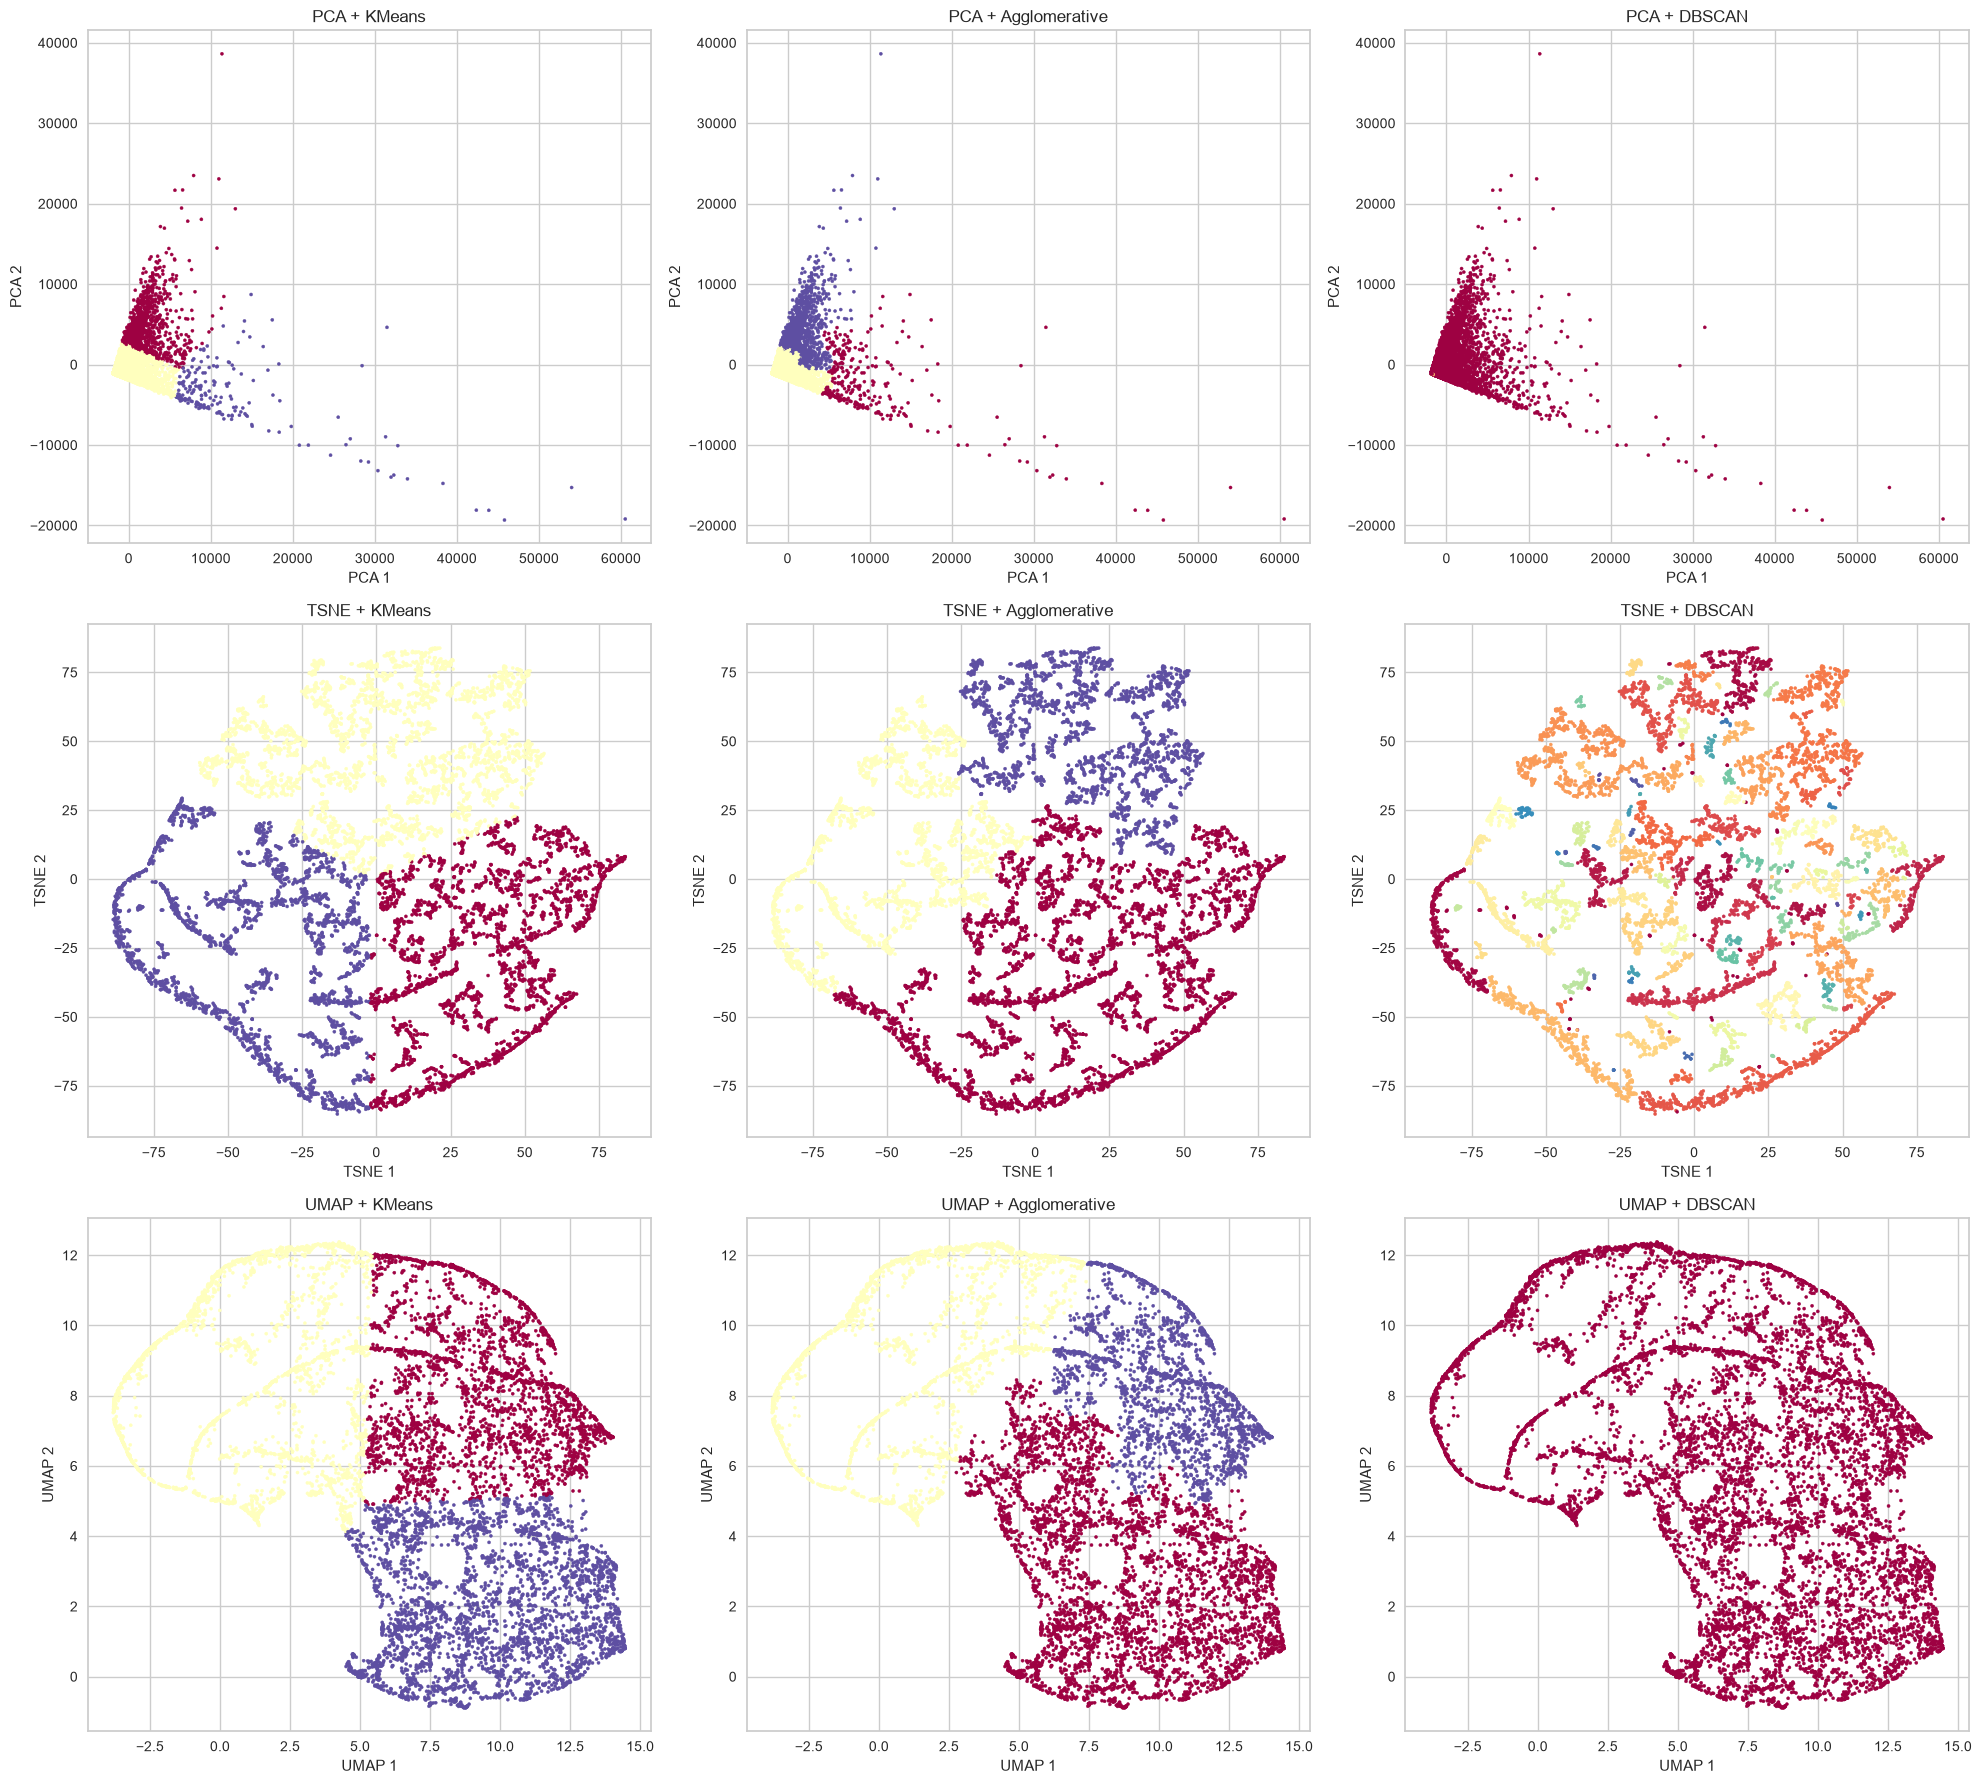

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(20, 18))

for i, (name, X) in enumerate(data.items()):
    for j, (method, labels) in enumerate(results[name].items()):

        axes[i, j].scatter(
            X[:, 0],
            X[:, 1],
            c=labels,
            cmap='Spectral',
            s=5
        )

        axes[i, j].set_title(f'{name} + {method}')
        axes[i, j].set_xlabel(f'{name} 1')
        axes[i, j].set_ylabel(f'{name} 2')

plt.tight_layout()
plt.show()

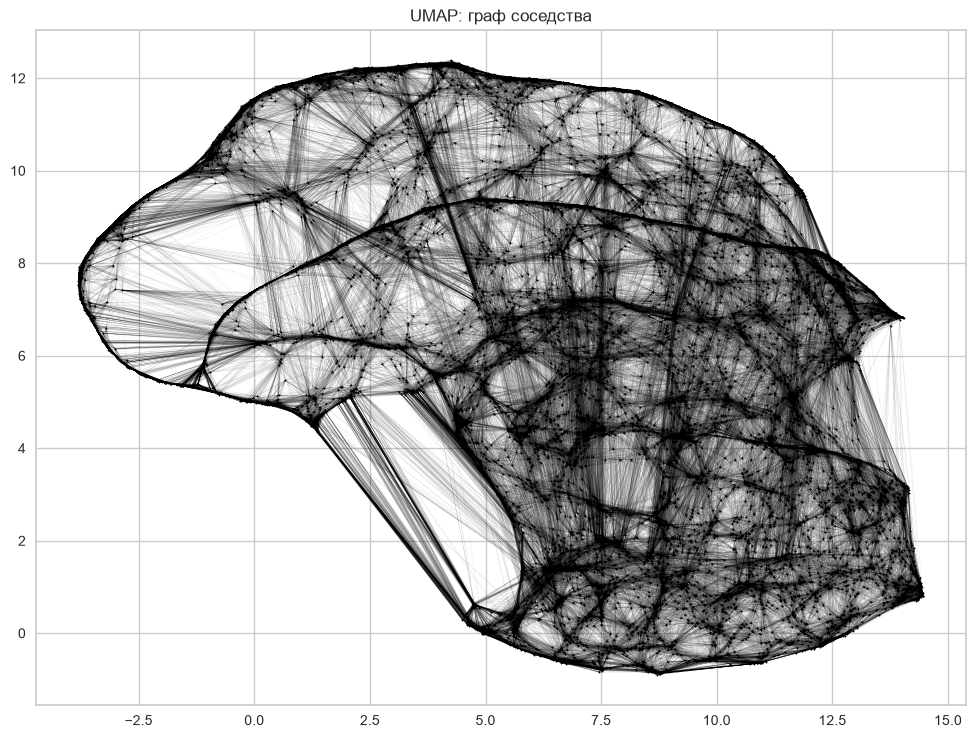

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from scipy.sparse import triu

# Получаем граф связей UMAP
graph = triu(ump.graph_, k=1).tocoo()

# Координаты точек
coords = kag_umap

# Создаём линии между связанными точками
edges = np.stack([
    coords[graph.row],
    coords[graph.col]
], axis=1)

fig, ax = plt.subplots(figsize=(12, 10))

# Рисуем связи
lines = LineCollection(
    edges,
    colors='black',
    linewidths=0.2,
    alpha=0.15
)

ax.add_collection(lines)

# Рисуем точки
ax.scatter(
    coords[:, 0],
    coords[:, 1],
    s=1,
    c='black'
)

ax.autoscale()
ax.set_aspect('equal')
ax.set_title('UMAP: граф соседства')

plt.show()

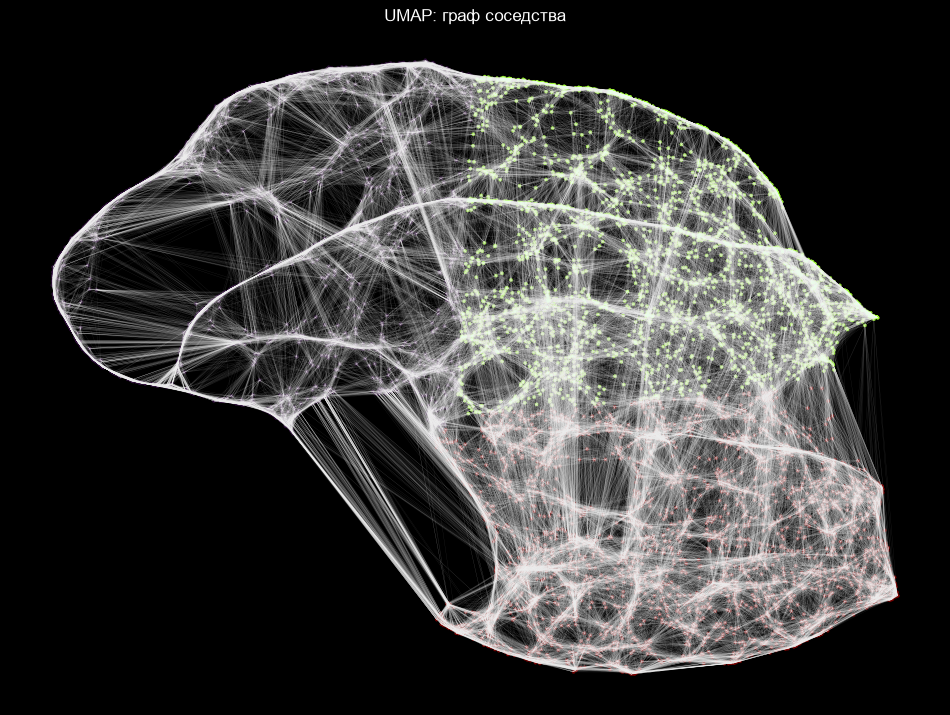

In [51]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from scipy.sparse import triu

# Получаем граф связей UMAP
graph = triu(ump.graph_, k=1).tocoo()

# Координаты точек
coords = kag_umap

# Создаём линии между связанными точками
edges = np.stack([
    coords[graph.row],
    coords[graph.col]
], axis=1)

fig, ax = plt.subplots(figsize=(12, 10))

# Чёрный фон
fig.patch.set_facecolor('black')
ax.set_facecolor('black')

# Рисуем связи
lines = LineCollection(
    edges,
    colors='white',
    linewidths=0.2,
    alpha=0.15
)

ax.add_collection(lines)

# Рисуем разноцветные точки по кластерам
ax.scatter(
    coords[:, 0],
    coords[:, 1],
    s=5,
    c=kag_km,
    cmap='turbo',
    alpha=0.9
)

ax.autoscale()
ax.set_aspect('equal')
ax.set_title('UMAP: граф соседства', color='white')
ax.axis('off')

plt.show()

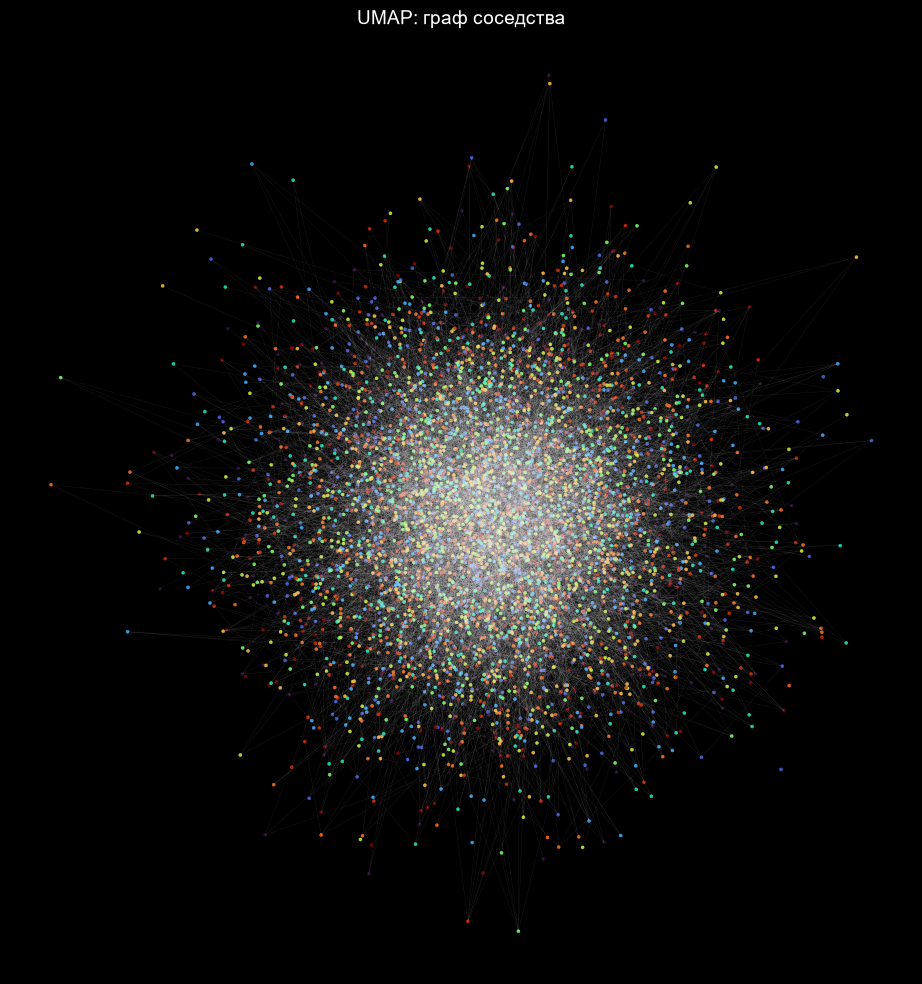

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.sparse import triu, coo_matrix
import umap

# ==========================================
# 1. БЛОК ГЕНЕРАЦИИ ДАННЫХ (Замените на свои)
# ==========================================
# Генерируем случайные данные для примера
np.random.seed(42)
n_samples = 5000

# Имитация координат UMAP (kag_umap)
kag_umap = np.random.randn(n_samples, 2) * 5

# Имитация меток кластеров (kag_km)
kag_km = np.random.randint(0, 10, size=n_samples)

# Имитация графа связей UMAP (ump.graph_)
# В реальности это разреженная матрица, полученная из reducer.graph_
# Для примера создадим случайный разреженный граф
row = np.random.randint(0, n_samples, 15000)
col = np.random.randint(0, n_samples, 15000)
data = np.ones(len(row))
ump_graph_ = coo_matrix((data, (row, col)), shape=(n_samples, n_samples))

# ==========================================
# 2. ВАШ КОД ДЛЯ ГРАФИКА
# ==========================================

# Получаем граф связей UMAP (только верхний треугольник, чтобы не дублировать линии)
graph = triu(ump_graph_, k=1).tocoo()

# Координаты точек
coords = kag_umap

# Создаём линии между связанными точками
# np.stack собирает пары координат для каждой связи
edges = np.stack([
    coords[graph.row],
    coords[graph.col]
], axis=1)

# Создаем фигуру
fig, ax = plt.subplots(figsize=(12, 10))

# Чёрный фон
fig.patch.set_facecolor('black')
ax.set_facecolor('black')

# Рисуем связи
lines = LineCollection(
    edges,
    colors='white',
    linewidths=0.2,
    alpha=0.15
)
ax.add_collection(lines)

# Рисуем разноцветные точки по кластерам
scatter = ax.scatter(
    coords[:, 0],
    coords[:, 1],
    s=5,               # Размер точек
    c=kag_km,          # Цвет по кластерам
    cmap='turbo',      # Палитра (очень яркая, подходит для черного фона)
    alpha=0.9          # Прозрачность точек
)

ax.autoscale()
ax.set_aspect('equal')
ax.set_title('UMAP: граф соседства', color='white', fontsize=14)
ax.axis('off')         # Отключаем оси

# Опционально: добавление цветовой шкалы (colorbar)
# cbar = plt.colorbar(scatter, ax=ax, fraction=0.046, pad=0.04)
# cbar.ax.yaxis.set_tick_params(color='white')
# plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='white')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

scores = {}

for name, X in data.items():
    for method, labels in results[name].items():

        # Для DBSCAN не учитываем шум при оценке кластеров
        if method == 'DBSCAN':
            mask = labels != -1
            X_score = X[mask]
            labels_score = labels[mask]
        else:
            X_score = X
            labels_score = labels

        n_clusters = len(set(labels_score))

        if 1 < n_clusters < len(labels_score):
            score = silhouette_score(X_score, labels_score)
            scores[(name, method)] = score

            print(f'{name} + {method}: {score:.3f}')
        else:
            print(f'{name} + {method}: Silhouette не рассчитывается')

PCA + KMeans: 0.632
PCA + Agglomerative: 0.607
PCA + DBSCAN: 0.538
TSNE + KMeans: 0.387
TSNE + Agglomerative: 0.345
TSNE + DBSCAN: 0.037
UMAP + KMeans: 0.410
UMAP + Agglomerative: 0.369
UMAP + DBSCAN: Silhouette не рассчитывается


In [ ]:
best_result = max(scores, key=scores.get)

best_name, best_method = best_result
best_score = scores[best_result]

print(f'Лучший метод: {best_name} + {best_method}')
print(f'Silhouette: {best_score:.3f}')

Лучший метод: PCA + KMeans
Silhouette: 0.632


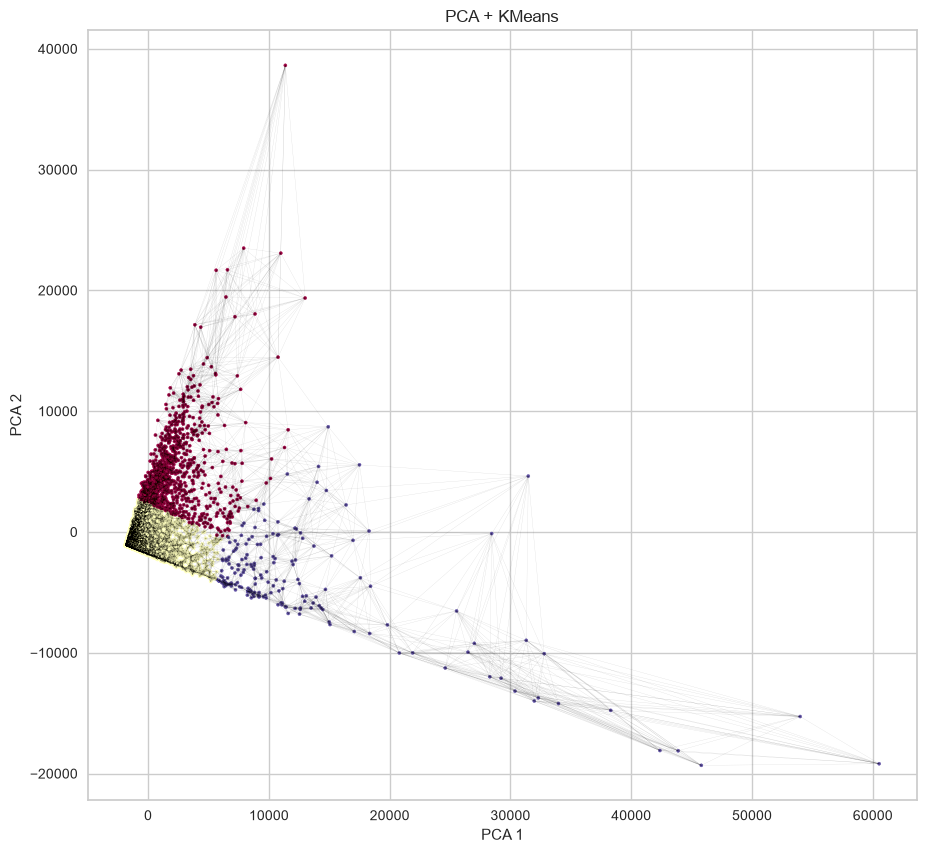

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from sklearn.neighbors import kneighbors_graph
from scipy.sparse import triu

# Строим граф ближайших соседей
graph = kneighbors_graph(
    best_X,
    n_neighbors=15,
    mode='connectivity',
    include_self=False
)

# Делаем связи симметричными
graph = graph.maximum(graph.T)

# Оставляем каждую связь только один раз
graph = triu(graph, k=1).tocoo()

# Получаем координаты линий
edges = np.stack([
    best_X[graph.row],
    best_X[graph.col]
], axis=1)

# Создаём график
fig, ax = plt.subplots(figsize=(12, 10))

# Рисуем связи между соседними точками
lines = LineCollection(
    edges,
    colors='black',
    linewidths=0.2,
    alpha=0.15
)

ax.add_collection(lines)

# Рисуем точки, окрашенные по кластерам
ax.scatter(
    best_X[:, 0],
    best_X[:, 1],
    c=best_labels,
    cmap='Spectral',
    s=5
)

ax.autoscale()
ax.set_aspect('equal')

ax.set_title(f'{best_name} + {best_method}')
ax.set_xlabel(f'{best_name} 1')
ax.set_ylabel(f'{best_name} 2')

plt.show()

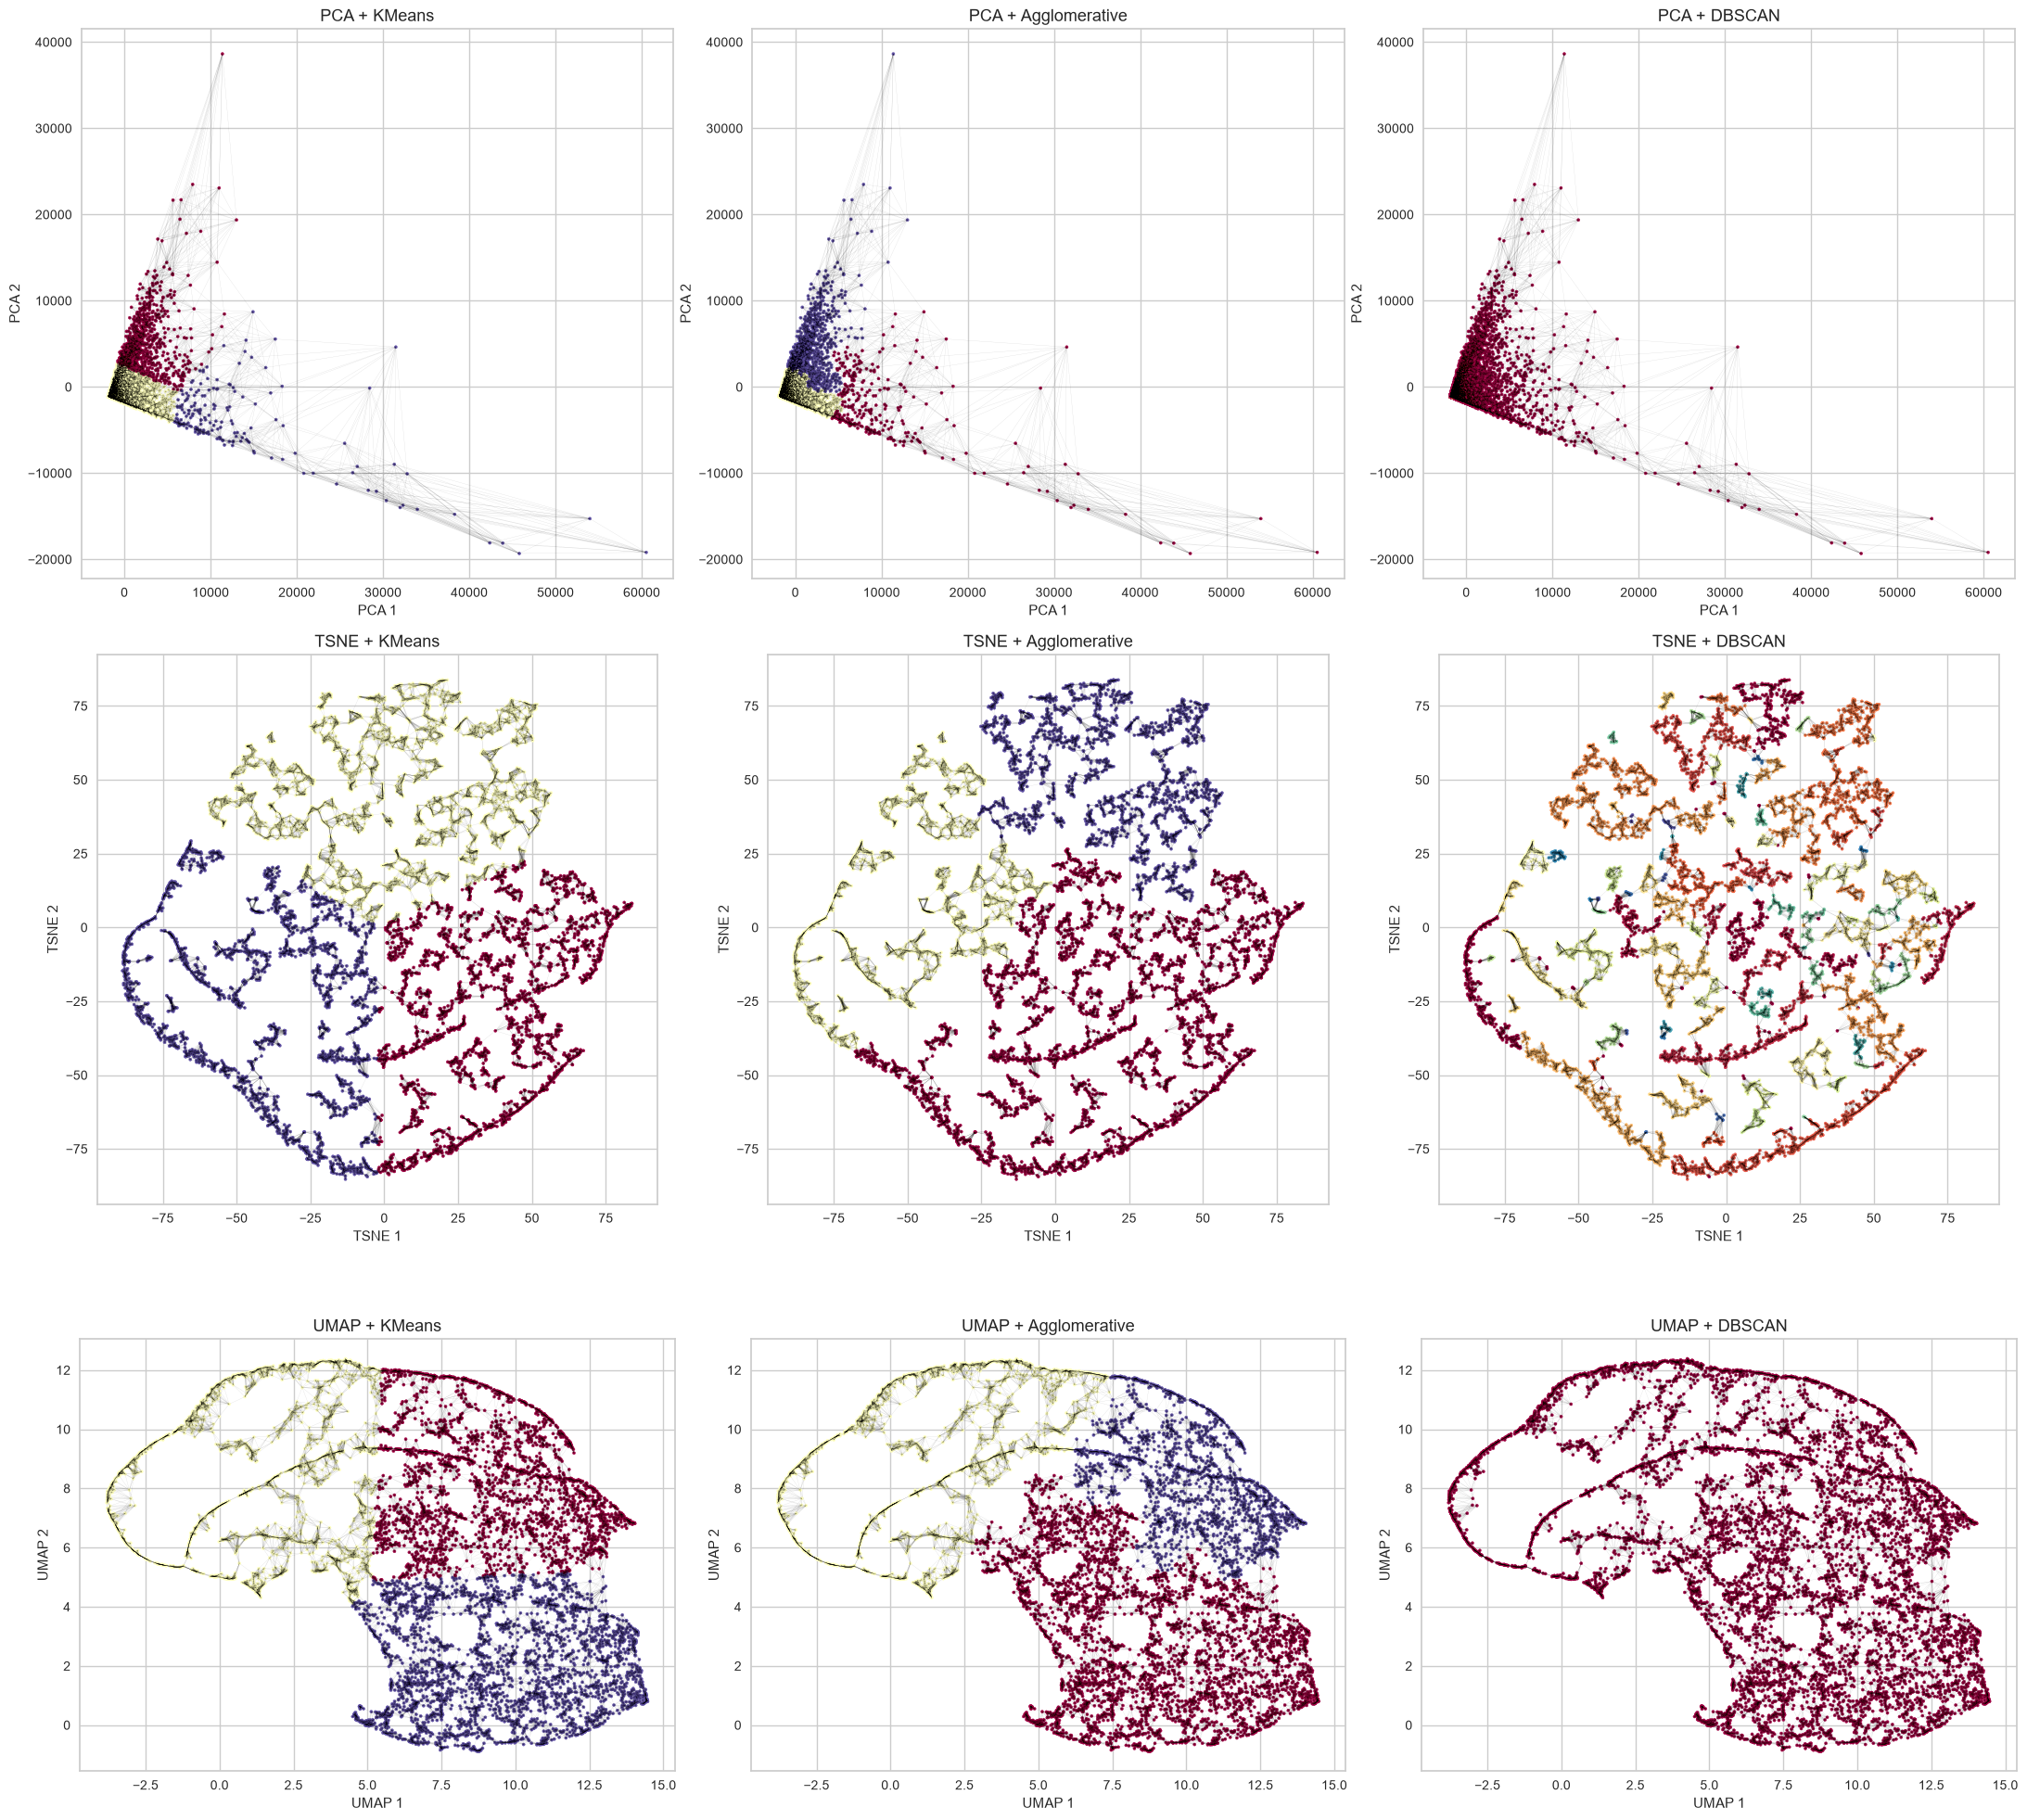

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from sklearn.neighbors import kneighbors_graph
from scipy.sparse import triu

fig, axes = plt.subplots(3, 3, figsize=(22, 20))

for i, (name, X) in enumerate(data.items()):
    for j, (method, labels) in enumerate(results[name].items()):

        ax = axes[i, j]

        # Строим граф ближайших соседей
        graph = kneighbors_graph(
            X,
            n_neighbors=15,
            mode='connectivity',
            include_self=False
        )

        graph = graph.maximum(graph.T)
        graph = triu(graph, k=1).tocoo()

        # Координаты линий
        edges = np.stack([
            X[graph.row],
            X[graph.col]
        ], axis=1)

        # Рисуем паутинку
        lines = LineCollection(
            edges,
            colors='black',
            linewidths=0.2,
            alpha=0.15
        )

        ax.add_collection(lines)

        # Рисуем точки по кластерам
        ax.scatter(
            X[:, 0],
            X[:, 1],
            c=labels,
            cmap='Spectral',
            s=5
        )

        ax.autoscale()
        ax.set_aspect('equal')
        ax.set_title(f'{name} + {method}', fontsize=13)

        ax.set_xlabel(f'{name} 1')
        ax.set_ylabel(f'{name} 2')

plt.tight_layout()
plt.show()